In [1]:
%mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 2.187 seconds
  Name           Version  Build                Channel
--------------------------------------------------------------------
+ pandas         3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
+ python-tzdata  2026.5   pyh5ded981_0         conda-forge
- pip            26.2.1   pyh145f28c_0         conda-forge


In [2]:
%mamba install scikit-learn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.048 seconds
  Name                Version     Build                Channel
----------------------------------------------------------------------------
+ brotli-python       1.2.0       py313h8faef1e_3      emscripten-forge-4x
+ certifi             2026.10.23  pyhd8ed1ab_0         conda-forge
+ charset-normalizer  3.5.1       pyhd8ed1ab_0         conda-forge
+ idna                3.20        pyh5ded981_0         conda-forge
+ joblib              1.6.0       py313h57e9779_0      emscripten-forge-4x
+ narwhals            2.27.1      pyh5ded981_0         conda-forge
+ pysocks             1.7.1       py313h1804a44_3      emscripten-forge-4x
+ requests            2.34.2      pyhcf101f3_0         conda-forge
+ scikit-learn        1.9.0       np23py313hb9816c2_0  emscripten-forge-4x
+ setupto

Split labels: <StringArray>
['train', 'test']
Length: 2, dtype: str

F1 — Test Confusion Matrix
                 Predicted normal  Predicted sag  Predicted swell  \
Actual normal                  90              0                0   
Actual sag                      0             44                0   
Actual swell                    0              0               36   
Actual harmonic                 3              0                0   

                 Predicted harmonic  
Actual normal                     0  
Actual sag                        1  
Actual swell                      0  
Actual harmonic                  36  

Per-class test recall:
normal: 100.0%
sag: 97.8%
swell: 100.0%
harmonic: 92.3%

Overall test accuracy: 98.1%


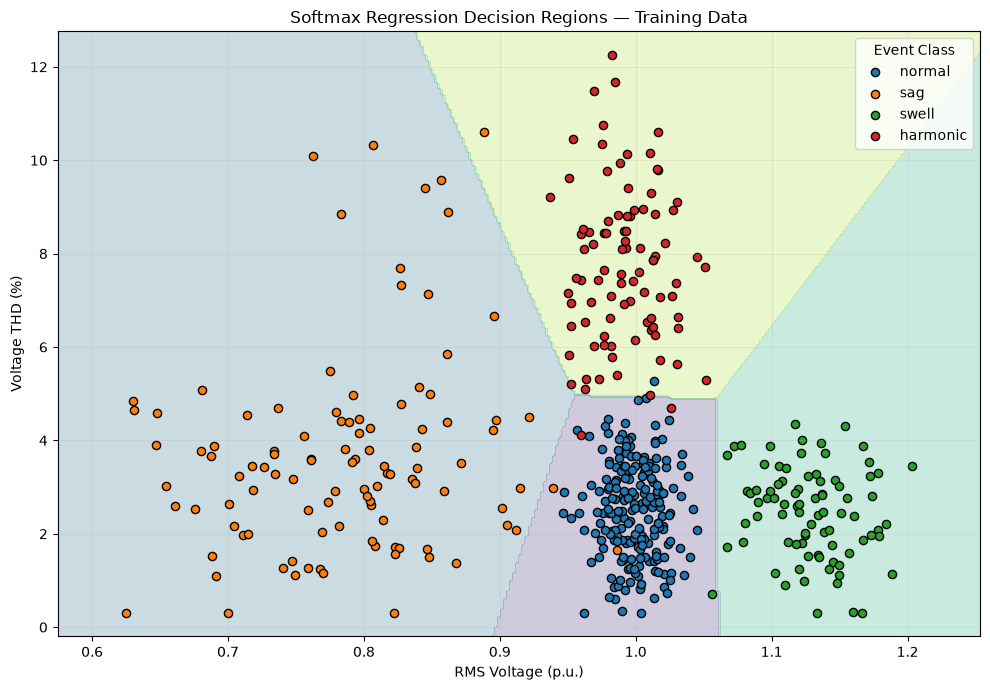


Decision-region plot saved as F1_regions.png


In [4]:
# F1 - Softmax Regression for Power Quality Events

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score

# Load the dataset
df_F = pd.read_csv("F_pq_events.csv")

features = ["rms_pu", "thd_pct"]
class_order = ["normal", "sag", "swell", "harmonic"]

# Check the dataset's split labels
print("Split labels:", df_F["split"].unique())

# Use the exact labels present in the dataset
train_F = df_F[df_F["split"] == "train"].copy()
test_F = df_F[df_F["split"] == "test"].copy()

if train_F.empty or test_F.empty:
    raise ValueError(
        "Training or test data is empty. Check df_F['split'].unique()."
    )

X_train = train_F[features]
y_train = train_F["event"]

X_test = test_F[features]
y_test = test_F["event"]

# Required pipeline
model_F = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=10, max_iter=2000)
)

# Fit using training data only
model_F.fit(X_train, y_train)

# Predict test classes
y_pred = model_F.predict(X_test)

# Confusion matrix: rows = true classes, columns = predicted classes
cm = confusion_matrix(
    y_test, y_pred, labels=class_order
)

print("\nF1 — Test Confusion Matrix")
print(pd.DataFrame(
    cm,
    index=[f"Actual {c}" for c in class_order],
    columns=[f"Predicted {c}" for c in class_order]
))

# Per-class recall
recalls = recall_score(
    y_test,
    y_pred,
    labels=class_order,
    average=None,
    zero_division=0
)

print("\nPer-class test recall:")
for class_name, recall in zip(class_order, recalls):
    print(f"{class_name}: {recall * 100:.1f}%")

# Overall test accuracy
accuracy = accuracy_score(y_test, y_pred) * 100
print(f"\nOverall test accuracy: {accuracy:.1f}%")

# ------------------------------------------
# Decision-region plot using training data
# ------------------------------------------

x_min = train_F["rms_pu"].min() - 0.05
x_max = train_F["rms_pu"].max() + 0.05
y_min = train_F["thd_pct"].min() - 0.5
y_max = train_F["thd_pct"].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = pd.DataFrame({
    "rms_pu": xx.ravel(),
    "thd_pct": yy.ravel()
})

grid_pred = model_F.predict(grid)

# Convert class names into numbers for the contour plot
class_to_num = {name: i for i, name in enumerate(class_order)}
zz = np.array(
    [class_to_num[c] for c in grid_pred]
).reshape(xx.shape)

plt.figure(figsize=(10, 7))

plt.contourf(
    xx, yy, zz,
    levels=np.arange(-0.5, len(class_order) + 0.5, 1),
    alpha=0.25,
    cmap="viridis"
)

# Overlay training samples
for class_name in class_order:
    subset = train_F[train_F["event"] == class_name]
    plt.scatter(
        subset["rms_pu"],
        subset["thd_pct"],
        label=class_name,
        edgecolors="black",
        s=35
    )

plt.xlabel("RMS Voltage (p.u.)")
plt.ylabel("Voltage THD (%)")
plt.title("Softmax Regression Decision Regions — Training Data")
plt.legend(title="Event Class")
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig("F1_regions.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nDecision-region plot saved as F1_regions.png")

In [5]:
# F2 - Predicted Class Probabilities

operating_points = pd.DataFrame({
    "rms_pu": [0.97, 0.84],
    "thd_pct": [5.0, 8.0]
})

# Predict probabilities for each class
probabilities = model_F.predict_proba(operating_points)

# Use the actual class order returned by the fitted model
probability_table = pd.DataFrame(
    probabilities,
    columns=model_F.classes_,
    index=[
        "RMS = 0.97 p.u., THD = 5.0%",
        "RMS = 0.84 p.u., THD = 8.0%"
    ]
)

print("F2 — Predicted Class Probabilities")
print(probability_table.round(3).to_string())

# Optional: show the most probable class at each operating point
print("\nMost probable class:")
for point, row in probability_table.iterrows():
    print(f"{point}: {row.idxmax()}")

F2 — Predicted Class Probabilities
                             harmonic  normal    sag  swell
RMS = 0.97 p.u., THD = 5.0%     0.469    0.42  0.110    0.0
RMS = 0.84 p.u., THD = 8.0%     0.002    0.00  0.998    0.0

Most probable class:
RMS = 0.97 p.u., THD = 5.0%: harmonic
RMS = 0.84 p.u., THD = 8.0%: sag


Number of sag events with THD > 6%: 19

Selected events:
 rms_pu  thd_pct event split
 0.8063    10.32   sag train
 0.7829     8.84   sag train
 0.8960     6.67   sag train
 0.8564     9.57   sag train
 0.8881    10.60   sag train
 0.7628    10.08   sag train
 0.8475     7.13   sag train
 0.8270     7.33   sag train
 0.8268     7.70   sag train
 0.8620     8.90   sag train
 0.8452     9.41   sag train
 0.8319    11.92   sag  test
 0.8445     8.54   sag  test
 0.8252     8.63   sag  test
 0.8001     9.36   sag  test
 0.7908     8.22   sag  test
 0.8805     9.68   sag  test
 0.8728     7.90   sag  test
 0.8908    11.21   sag  test


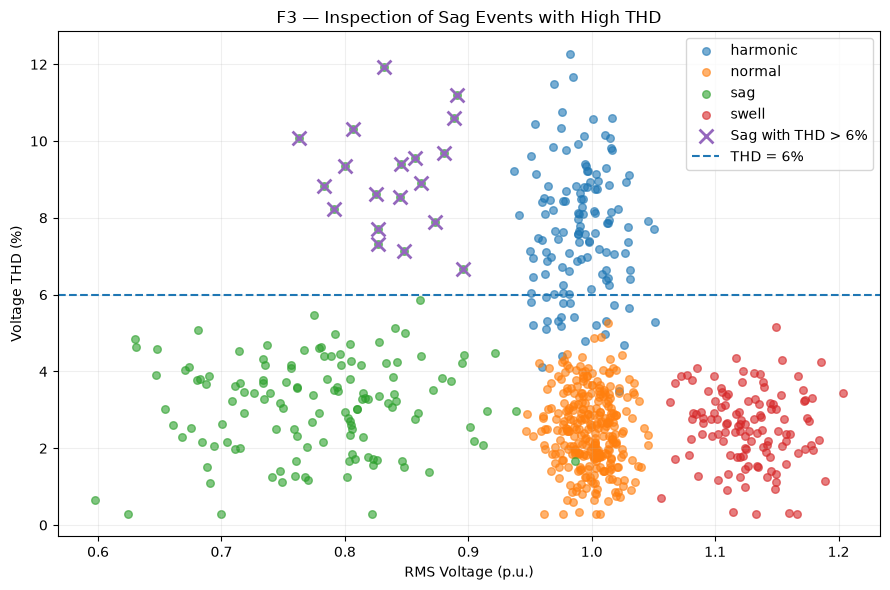


Plot saved as F3_suspicious_sag.png


In [6]:
# F3 bhi kar lete hainnn

import pandas as pd
import matplotlib.pyplot as plt

# Loading dataset
df_F = pd.read_csv("F_pq_events.csv")

# Selecting events labelled sag with THD greater than 6%
suspicious = df_F[
    (df_F["event"] == "sag") &
    (df_F["thd_pct"] > 6)
].copy()

# Counting selected events
print("Number of sag events with THD > 6%:", len(suspicious))

# Displaying selected records
print("\nSelected events:")
print(suspicious.to_string(index=False))

# Plotting all events and highlight the selected records
plt.figure(figsize=(9, 6))

for label, group in df_F.groupby("event"):
    plt.scatter(
        group["rms_pu"],
        group["thd_pct"],
        label=label,
        alpha=0.6,
        s=30
    )

# Highlight suspicious sag events
plt.scatter(
    suspicious["rms_pu"],
    suspicious["thd_pct"],
    marker="x",
    s=100,
    linewidths=2,
    label="Sag with THD > 6%"
)

plt.axhline(
    y=6,
    linestyle="--",
    label="THD = 6%"
)

plt.xlabel("RMS Voltage (p.u.)")
plt.ylabel("Voltage THD (%)")
plt.title("F3 — Inspection of Sag Events with High THD")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("F3_suspicious_sag.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nPlot saved as F3_suspicious_sag.png")
